# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [3]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [4]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


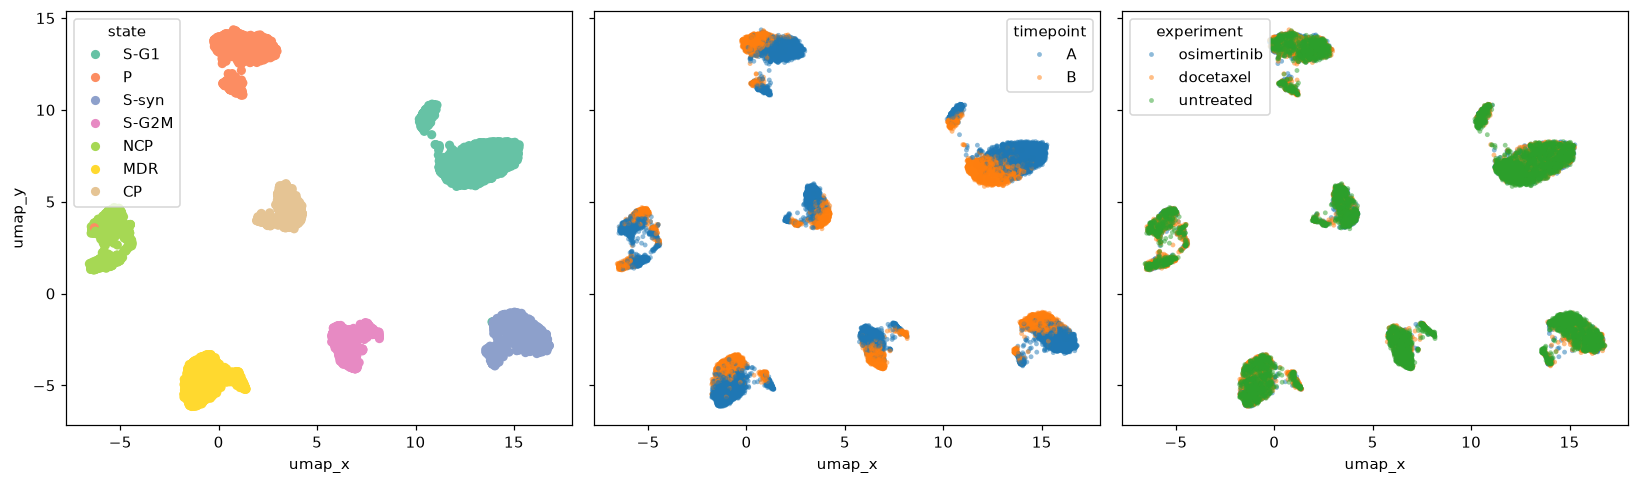

In [5]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [6]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [7]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [8]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [9]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [10]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [11]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

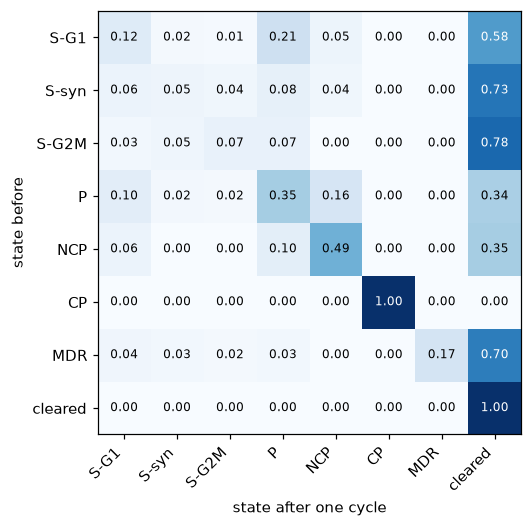

In [12]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

Yes! CP is another approximately absorbing state under osimertinib, in addition to the cleared state because its transition probability of staying in CP is 1.00. This indicates that CP cells are drug-tolerant or resistant to osimertinib.
Therefore, osimertinib does not eliminate all cells, as some cells remain in the persister state even under treatment.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [13]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [14]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [15]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

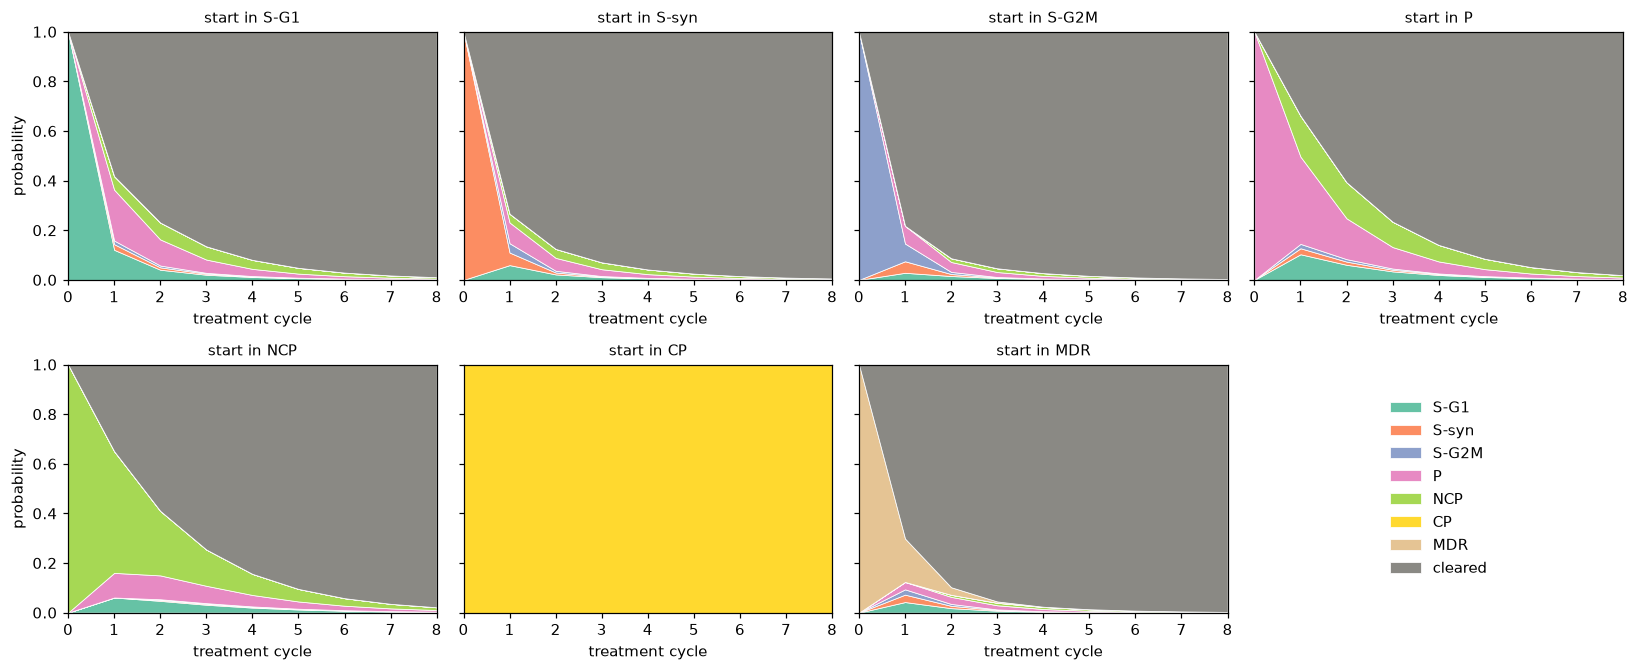

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [16]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [17]:

# Calculate the probability distribution after 8 cycles
N_CYCLES = 8

results = {}

for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, N_CYCLES)
    results[s] = traj

# Display the probability distribution after 8 cycles
final_results = pd.DataFrame(
    {s: results[s][-1] for s in STATES},
    index=OUTCOMES
).T

print("Probability distribution after 8 cycles:")
display(final_results.round(3))


Probability distribution after 8 cycles:


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
S-G1,0.001,0.0,0.0,0.003,0.005,0.0,0.0,0.989
S-syn,0.001,0.0,0.0,0.002,0.003,0.0,0.0,0.994
S-G2M,0.000,0.0,0.0,0.001,0.002,0.0,0.0,0.996
P,0.003,0.0,0.0,0.006,0.010,0.0,0.0,0.981
NCP,0.003,0.0,0.0,0.007,0.011,0.0,0.0,0.978
CP,0.000,0.0,0.0,0.000,0.000,1.0,0.0,0.000
MDR,0.000,0.0,0.0,0.001,0.001,0.0,0.0,0.997


- CP survives because it is an absorbing state with a 1.00 probability of remaining CP.

- S-G1, S-syn, S-G2M, P, NCP, and MDR: These states can eventually be eliminated because they have pathways to the cleared state.

- Cleared remains cleared with probability 1.00.

- NCP has the lowest probability of being cleared after eight cycles (0.978).
Therefore, NCP appears to persist the longest among the states that can eventually be cleared.

- CP sticks around for the most cycles of drug. CP is an absorbing state. Its probability of remaining CP is 1.00. This means cells starting in CP remain in that state throughout treatment

In [18]:

alive_after_3 = {}

for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, 3)

    # Sum probabilities of all living states
    alive = sum(
        traj[3, OUTCOMES.index(state)]
        for state in STATES
        if state != "cleared"
    )

    alive_after_3[s] = alive

alive_df = pd.Series(alive_after_3)

display(alive_df.sort_values(ascending=False).round(4))

print("Highest proportion alive:", alive_df.idxmax())


CP       1.0000
NCP      0.2543
P        0.2344
S-G1     0.1352
S-syn    0.0707
S-G2M    0.0467
MDR      0.0451
dtype: float64

Highest proportion alive: CP


- CP results in the highest proportion of living cells after three treatment cycles (100%).

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

S-G1       0.247
S-syn      0.148
S-G2M      0.099
P          0.153
NCP        0.102
CP         0.097
MDR        0.153
cleared    0.000
dtype: float64


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


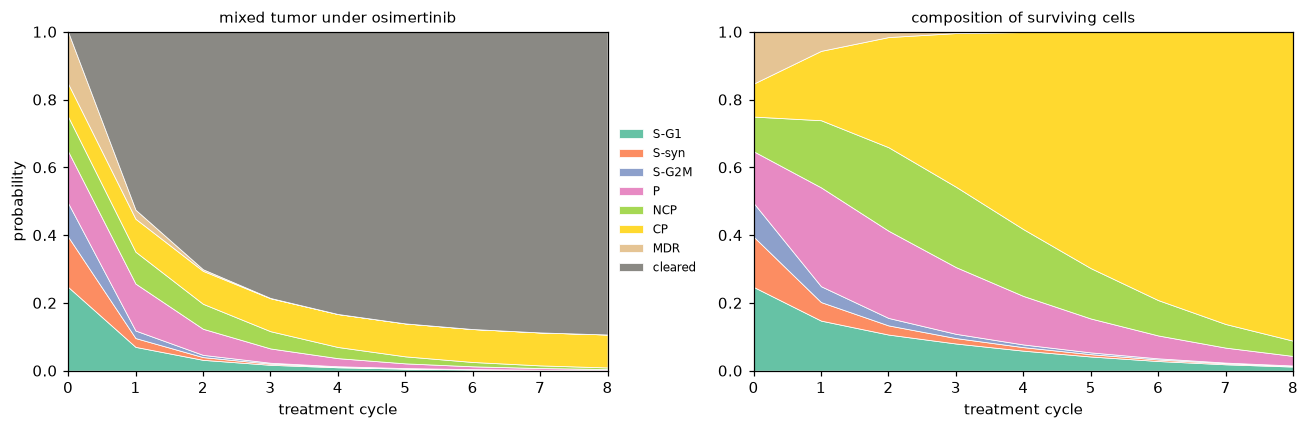

In [19]:
# starting vector: fraction of cells in each state at timepoint A, all three experiments pooled
pi_mix = (cells[cells.timepoint == "A"]["state"]
          .value_counts(normalize=True)
          .reindex(OUTCOMES, fill_value=0)
          .to_numpy())
print(pd.Series(pi_mix, index=OUTCOMES).round(3))

# evolve pi_mix under osimertinib
traj_mix = evolve(pi_mix, P_hat.to_numpy(), N_CYCLES)
display(pd.DataFrame(traj_mix, columns=OUTCOMES).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_trajectory(traj_mix, axes[0], "mixed tumor under osimertinib")
axes[0].set_ylabel("probability")
axes[0].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)


alive = traj_mix[:, :-1]
alive_share = alive / alive.sum(axis=1, keepdims=True)
plot_trajectory(np.column_stack([alive_share, np.zeros(len(alive_share))]),
                axes[1], "composition of surviving cells")
plt.tight_layout()
plt.show()


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP dominates the remaining cluster of living cells. While other tumor states steadily decline across the cycles, CP remains fixed at exactly 9.7% (0.097) of the total population every cycle. CP represents an absorbing state under this treatment condition. Cells that start in or transition into this state remain there indefinitely.

The long-run endpoint represents the stationary or limiting distribution of the Markov chain. In here, an absorbing state like CP is characterized by a diagonal probability of exactly \(1\) (\(P_{i,i} = 1\)), meaning no transitions out of that state are possible.


## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [20]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
def transition_matrix(experiment):
    '''Estimate the square transition matrix (with an absorbing cleared row) for one experiment.'''
    d = cells[cells["experiment"] == experiment]
    A = d[d.timepoint == "A"][["lineage_tag", "state"]]
    B = d[d.timepoint == "B"][["lineage_tag", "state"]]
    pr = pd.merge(A, B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pr["state_B"] = pr["state_B"].fillna("cleared")
    c = (pd.crosstab(pr.state_A, pr.state_B)
           .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P = c.div(c.sum(axis=1), axis=0)
    P.loc["cleared"] = [0] * len(STATES) + [1]
    assert np.allclose(P.sum(axis=1), 1)
    return P

P_osi_df     = P_hat
P_doc_df     = transition_matrix("docetaxel")
P_holiday_df = transition_matrix("untreated")

P_osi     = P_osi_df.to_numpy()
P_doc     = P_doc_df.to_numpy()
P_holiday = P_holiday_df.to_numpy()


In [21]:
#Plot the transition matrices for docetaxel and the drug holiday.

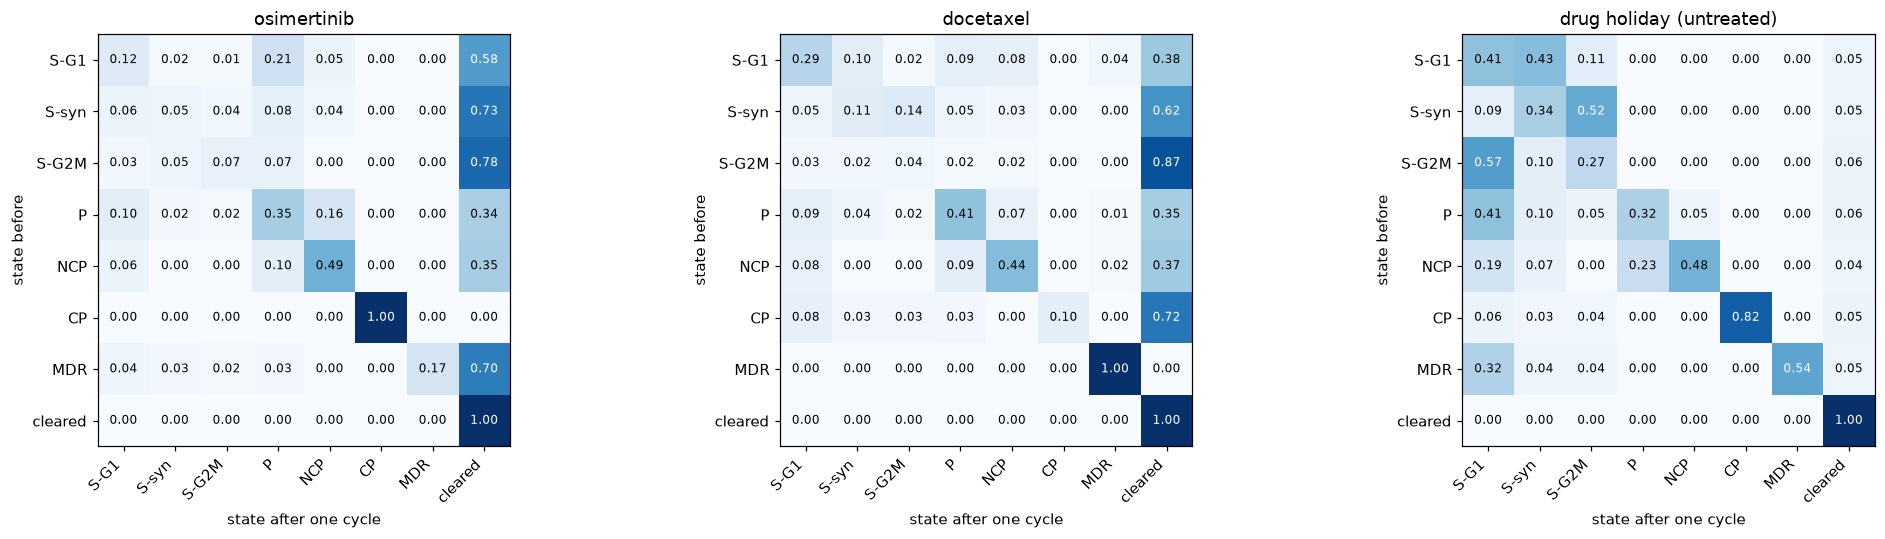

In [22]:
#Plot the transition matrices for docetaxel and the drug holiday.
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
show_matrix(P_osi_df, "osimertinib", axes[0])
show_matrix(P_doc_df, "docetaxel", axes[1])
show_matrix(P_holiday_df, "drug holiday (untreated)", axes[2])
plt.tight_layout()
plt.show()


In [23]:
# Simulate the evolution of pi_mix under docetaxel 

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


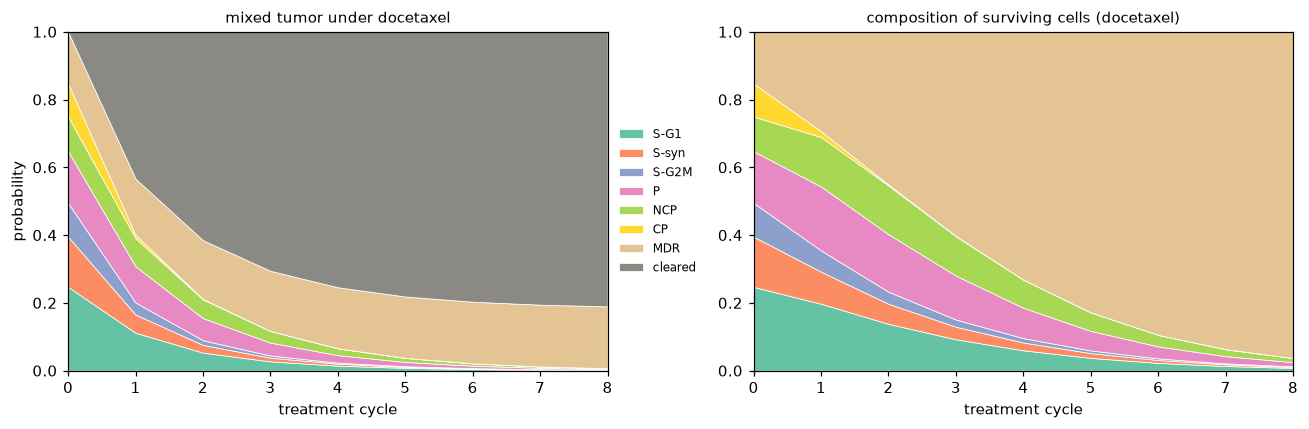

In [24]:
# Simulate the evolution of pi_mix under docetaxel 
traj_doc = evolve(pi_mix, P_doc, N_CYCLES)
display(pd.DataFrame(traj_doc, columns=OUTCOMES).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_trajectory(traj_doc, axes[0], "mixed tumor under docetaxel")
axes[0].set_ylabel("probability")
axes[0].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)

alive = traj_doc[:, :-1]
alive_share = alive / alive.sum(axis=1, keepdims=True)
plot_trajectory(np.column_stack([alive_share, np.zeros(len(alive_share))]),
                axes[1], "composition of surviving cells (docetaxel)")
plt.tight_layout()
plt.show()


1. The transition matrices show that docetaxel and osimertinib affect the cell states differently. Docetaxel is effective against CP cells, clearing 72% of them, and against S-G2M cells, clearing 87%. However, MDR is an absorbing state under docetaxel because 100% of MDR cells remain MDR, making them resistant to the treatment. Under a drug holiday, very few cells are cleared (around 5%), and cells mainly move between different states. CP and MDR tend to remain in their states but can still transition to other states, so neither is absorbing. In comparison, CP is an absorbing state under osimertinib because 100% of CP cells remain CP. Overall, the absorbing states are CP under osimertinib, MDR under docetaxel, and cleared under all three conditions.

2. Everything except MDR is cleared. MDR rises from 15.3% to about 18.3% of the original cells, because some S-G1, P and NCP cells convert into MDR before they die. After 8 cycles, MDR is about 96% of the surviving cells, and in the long run it's 100%: π ≈ (0, 0, 0, 0, 0, 0, 0.183, 0.817). Like osimertinib, docetaxel alone can't cure the mixed tumor. It just leaves a different resistant state behind. Because each drug clears the other drug's resistant state, combining or alternating them looks promising, provided cells don't convert into the other drug's resistant state faster than they're killed.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

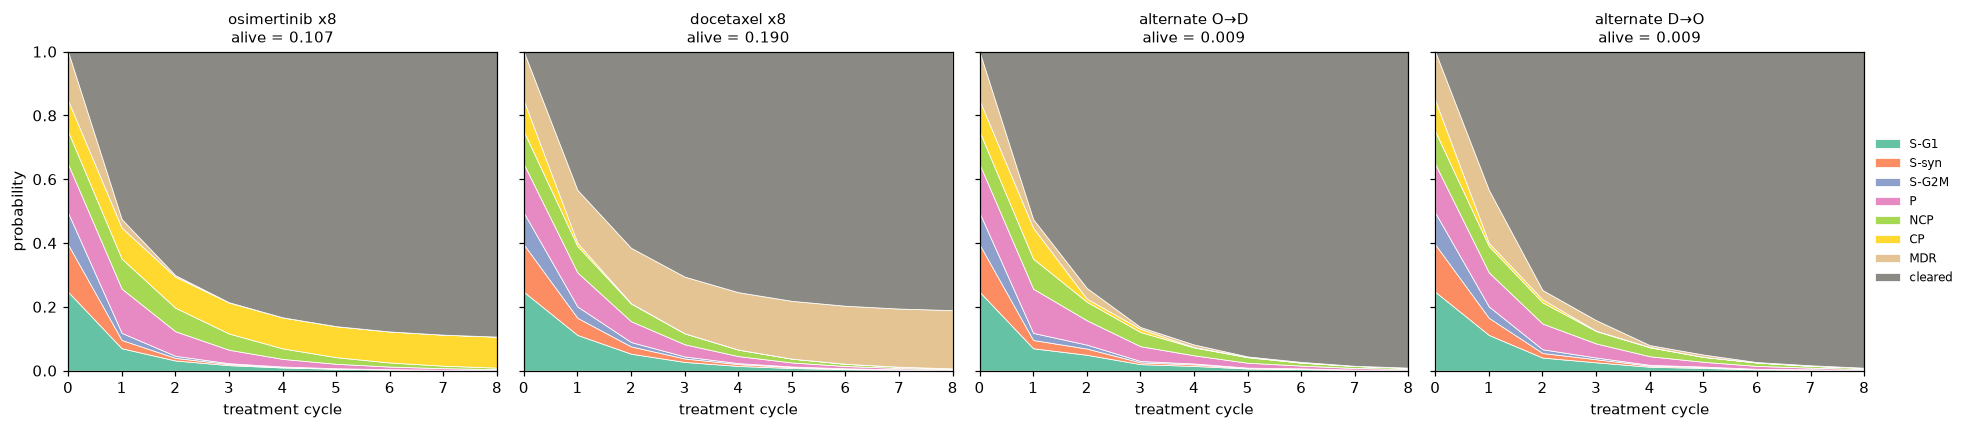

,OD x4,H + OD x4 (9 cycles),H then ODODODO,ODOD H ODO
mix,0.0094,0.0078,0.0125,0.0115
S-G1,0.0099,0.0066,0.0107,0.0119
S-syn,0.0051,0.0043,0.0069,0.0062
S-G2M,0.0032,0.0070,0.0113,0.0038
P,0.0170,0.0112,0.0180,0.0205
NCP,0.0190,0.0151,0.0243,0.0231
CP,0.0064,0.0061,0.0104,0.0084
MDR,0.0048,0.0061,0.0096,0.0064


,osimertinib x8,docetaxel x8,alternate O→D,alternate D→O
mix,0.1066,0.1896,0.0094,0.0092
S-G1,0.0108,0.0727,0.0099,0.0109
S-syn,0.0056,0.0124,0.0051,0.0047
S-G2M,0.0036,0.0059,0.0032,0.0021
P,0.0190,0.0545,0.0170,0.0154
NCP,0.0216,0.0681,0.0190,0.0172
CP,1.0000,0.0101,0.0064,0.0036
MDR,0.0029,1.0000,0.0048,0.0073


cycles needed to get below 1% alive (NaN = never):


,O,D,OD,DO
mix,NaN,NaN,8,8
S-G1,9.0,NaN,8,9
S-syn,7.0,10.0,7,7
S-G2M,6.0,6.0,6,6
P,10.0,NaN,9,9
NCP,10.0,NaN,10,10
CP,NaN,9.0,8,7
MDR,6.0,NaN,7,8


In [25]:
## Add code here
MATS = {"O": P_osi, "D": P_doc, "H": P_holiday}

def run_schedule(pi0, schedule):
    '''Apply a schedule string like "ODOD..." one cycle at a time; return the trajectory.'''
    traj = [np.asarray(pi0, dtype=float)]
    for drug in schedule:
        traj.append(traj[-1] @ MATS[drug])
    return np.array(traj)

def alive_after(pi0, schedule):
    return 1 - run_schedule(pi0, schedule)[-1, -1]

# --- 1 & 2: 8 cycles of each schedule on the mixed tumor ---
schedules = {"osimertinib x8": "O"*8, "docetaxel x8": "D"*8,
             "alternate O→D": "OD"*4, "alternate D→O": "DO"*4}

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (name, sch) in zip(axes, schedules.items()):
    plot_trajectory(run_schedule(pi_mix, sch), ax, f"{name}\nalive = {alive_after(pi_mix, sch):.3f}")
axes[0].set_ylabel("probability")
axes[-1].legend(OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

# --- 3: drug holidays (8 cycles with a holiday swapped in, and 1 extra holiday cycle) ---
holiday_scheds = {"OD x4": "OD"*4, "H + OD x4 (9 cycles)": "H" + "OD"*4,
                  "H then ODODODO": "HODODODO", "ODOD H ODO": "ODODHODO"}
starts = {"mix": pi_mix, **{s: basis(s, P_hat) for s in STATES}}
display(pd.DataFrame({k: {s: alive_after(p, sch) for s, p in starts.items()}
                      for k, sch in holiday_scheds.items()}).round(4))

# --- 4: every starting state x every schedule; and cycles needed to get <1% alive ---
grid = pd.DataFrame({k: {s: alive_after(p, sch) for s, p in starts.items()}
                     for k, sch in schedules.items()})
display(grid.round(4))

def cycles_to_clear(pi0, pattern, threshold=0.01, max_cycles=30):
    pi = np.asarray(pi0, float)
    for t in range(1, max_cycles + 1):
        pi = pi @ MATS[pattern[(t - 1) % len(pattern)]]
        if 1 - pi[-1] < threshold:
            return t
    return np.nan          # never clears (absorbing resistant state)

needed = pd.DataFrame({name: {s: cycles_to_clear(p, pat) for s, p in starts.items()}
                       for name, pat in {"O": "O", "D": "D", "OD": "OD", "DO": "DO"}.items()})
print("cycles needed to get below 1% alive (NaN = never):")
needed


1. Single drugs vs. alternating (8 cycles, mixed tumor). Osimertinib ×8 leaves 10.7% of cells alive, all CP. Docetaxel ×8 leaves 19.0% alive, nearly all MDR. Alternating leaves only about 0.9% alive. Neither drug can clear its own resistant state, but each one clears the other's. Docetaxel kills CP (72% per cycle) and osimertinib kills MDR (70% per cycle), so alternating removes both absorbing traps.

2. Does the starting drug matter? Barely, for this tumor: O→D leaves 0.94% alive and D→O leaves 0.92%, and both get below 1% in 8 cycles. Order only matters for single-state tumors: start with the drug that kills the dominant state. A CP tumor does better starting with D (0.36% vs 0.64%), and an MDR tumor does better starting with O (0.48% vs 0.73%).

3. When does a drug holiday help? A holiday kills almost nothing (about 5% per cycle), so swapping one into an 8-cycle schedule always leaves more cells alive than alternating drugs. It helps only as an extra cycle when the tumor is mostly persisters (P/NCP) or resistant cells. Without drug, those cells revert to the drug-sensitive S-G1 state (P→S-G1 = 0.41, MDR→S-G1 = 0.32). For example, adding one holiday before alternating cuts a P tumor from 1.7% to 1.1% alive, and the mixed tumor from 0.94% to 0.78%.

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [26]:
rng = np.random.default_rng(100)

In [27]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [28]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

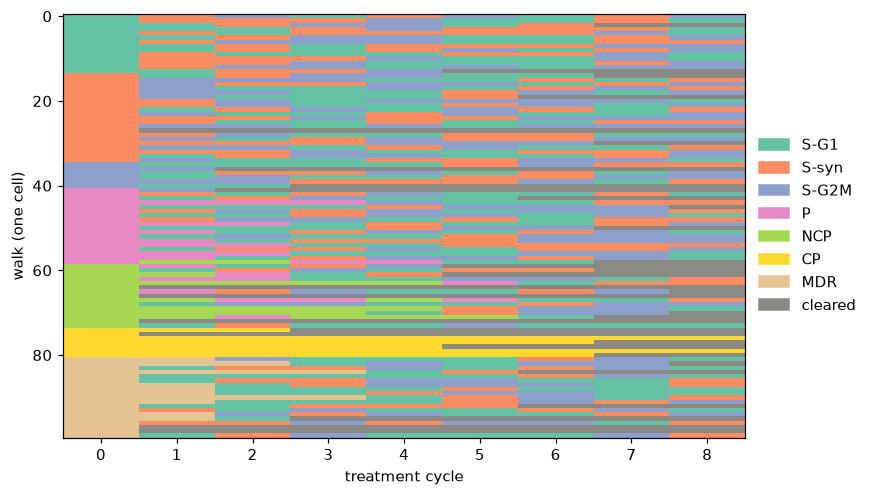

In [29]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [30]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

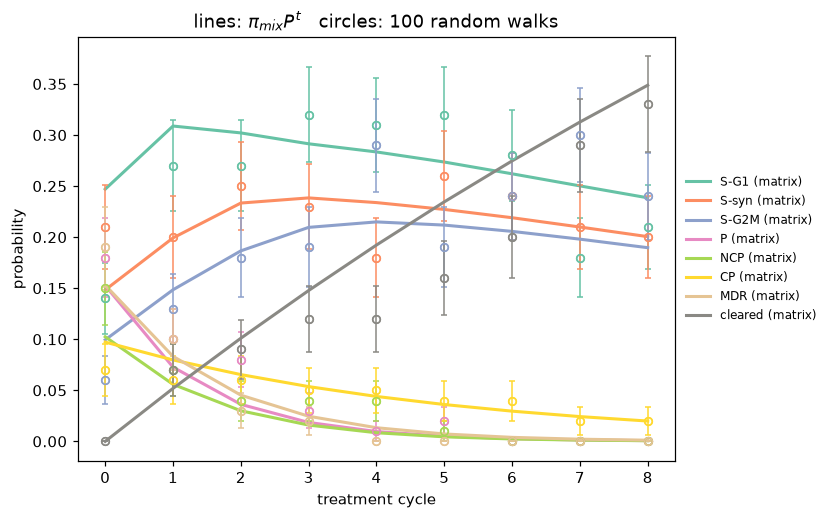

In [31]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

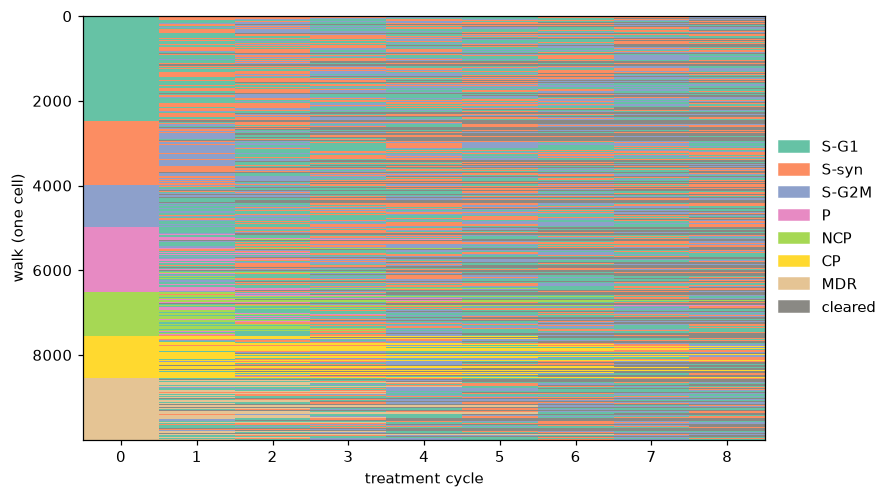

In [32]:
# Changing the number of random walks to 10,000
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [33]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

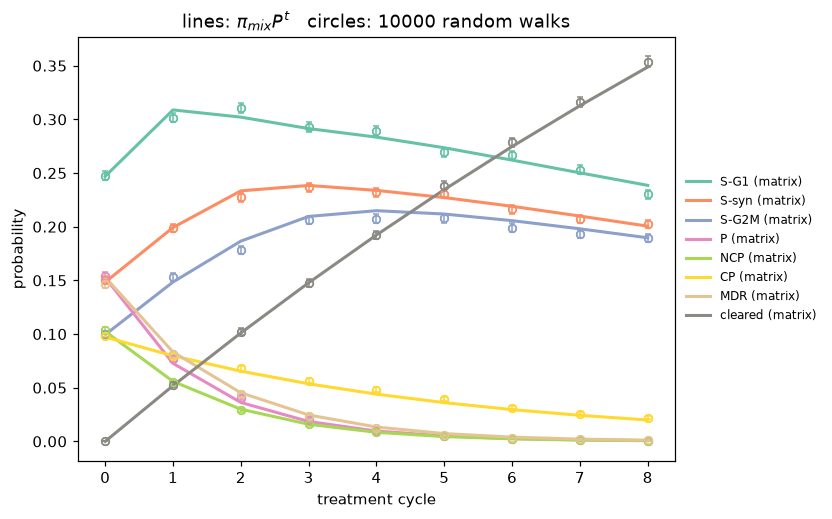

In [34]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

When N_WALKS increases from 100 to 10_000, the gap between the circles and the lines shrinks dramatically, with the circles sitting almost directly on top of the solid lines and the error bars becoming nearly invisible. 

This happens because of the Law of Large Numbers. The solid lines represent the exact theoretical probabilities ($\pi_{\text{mix}}P^t$) derived from the Markov transition matrix, while the circles represent empirical averages from random simulations. With only 100 walks, random sampling fluctuations cause noticeable deviations from the true probabilities. Increasing the sample size to 10,000 reduces the standard error (by a factor of $\sqrt{100} = 10$), causing the empirical simulation results to converge closely to the theoretical values.


## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [35]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

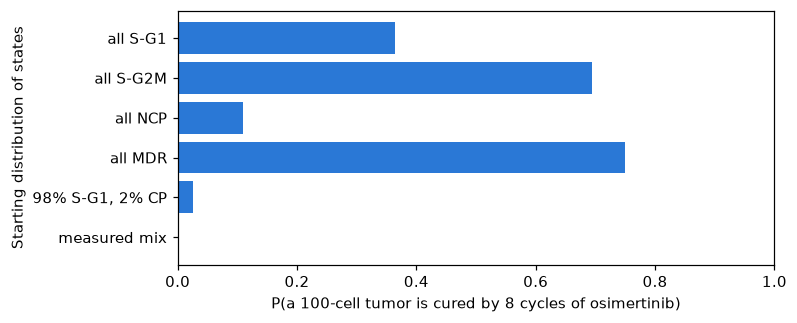

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [36]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

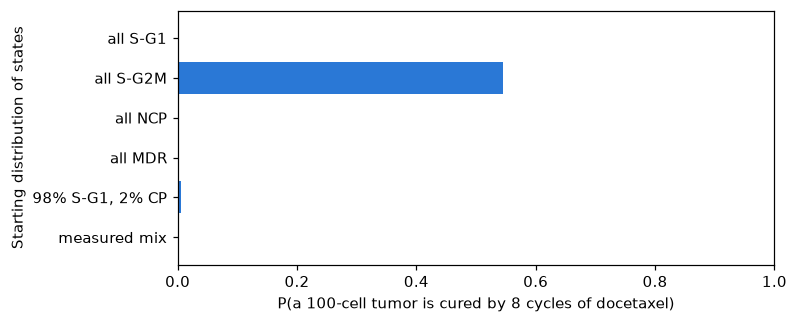

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.805,0.0
all S-G2M,0.545,0.610,0.0
all NCP,0.000,6.690,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.005,6.985,0.0
measured mix,0.000,18.955,0.0


In [37]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of docetaxel)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

All docetaxel produces very low mean cell survival across most starting populations. However, S-G2M shows the highest survival (0.580), suggesting greater resistance to docetaxel. The results also show that the initial cell population influences treatment effectiveness and the composition of surviving cells.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [38]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test



<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

% of tumors with > 10% permanently resistant cells


cycles,2,4,6,8,10,12,16
treatment,,,,,,,
Osimertinib alone,0.0,83.0,92.0,93.0,95.0,96.0,98.0
Docetaxel alone,0.0,5.0,13.0,20.0,21.0,12.0,12.0
Alternating OD,0.0,50.0,65.0,73.0,77.0,82.0,71.0
Docetaxel + holiday,0.0,1.0,20.0,37.0,52.0,57.0,62.0


8 cycles: mean PR fraction, 95% CI, one-sided t-test vs 10%


,mean PR fraction,SEM,CI low,CI high,p (H0: mean <= 10%)
treatment,,,,,
Osimertinib alone,0.1151,0.0010,0.1132,0.1170,0.0000
Docetaxel alone,0.0915,0.0010,0.0896,0.0934,1.0000
Alternating OD,0.1063,0.0010,0.1043,0.1083,0.0000
Docetaxel + holiday,0.0973,0.0009,0.0956,0.0990,0.9985


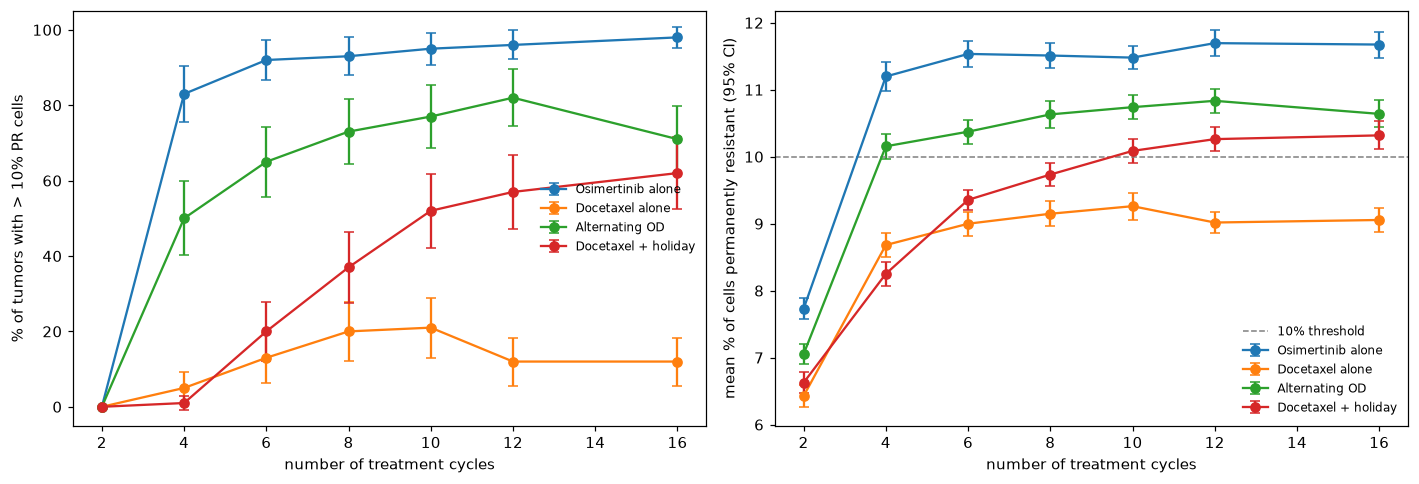

In [ ]:
# % of tumors with >10% permanently resistant (PR) cells, per treatment and number of cycles =====
from scipy import stats

MATS = {"O": P_osi, "D": P_doc, "H": P_holiday}
PERSISTERS = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]
TREATMENTS = {"Osimertinib alone": "O", "Docetaxel alone": "D",
              "Alternating OD": "OD", "Docetaxel + holiday": "DH"}
CYCLE_COUNTS = [2, 4, 6, 8, 10, 12, 16]
N_TUMORS_PR, N_CELLS_PR, THRESH = 100, 1000, 0.10
rng_pr = np.random.default_rng(5030)

def tumor_walks(pi0, schedule, n_cells, rng):
    '''All n_cells random walks of one tumor at once (inverse-CDF method), one matrix per cycle.'''
    s = rng.choice(len(pi0), size=n_cells, p=pi0)
    path = [s]
    for drug in schedule:
        cdf = MATS[drug].cumsum(axis=1)
        s = np.minimum((rng.random(n_cells)[:, None] > cdf[s]).sum(axis=1), len(OUTCOMES) - 1)
        path.append(s)
    return np.array(path).T                      # shape (n_cells, n_cycles + 1)

def fraction_PR(walks, k=3):
    '''Fraction of cells that spend >= k consecutive time points in P or NCP.'''
    in_pers = np.isin(walks, PERSISTERS)
    run = np.zeros(len(walks), dtype=int); longest = np.zeros(len(walks), dtype=int)
    for t in range(walks.shape[1]):
        run = np.where(in_pers[:, t], run + 1, 0)
        longest = np.maximum(longest, run)
    return np.mean(longest >= k)

rows = []
for name, pattern in TREATMENTS.items():
    for n_cyc in CYCLE_COUNTS:
        schedule = (pattern * n_cyc)[:n_cyc]
        f = np.array([fraction_PR(tumor_walks(pi_mix, schedule, N_CELLS_PR, rng_pr))
                      for _ in range(N_TUMORS_PR)])
        sem = f.std(ddof=1) / np.sqrt(len(f))
        p_hat = np.mean(f > THRESH)                               # share of tumors over 10%
        p_se = np.sqrt(p_hat * (1 - p_hat) / len(f))
        rows.append({"treatment": name, "cycles": n_cyc,
                     "mean PR fraction": f.mean(), "SEM": sem,
                     "CI low": f.mean() - 1.96 * sem, "CI high": f.mean() + 1.96 * sem,
                     "p (H0: mean <= 10%)": stats.ttest_1samp(f, THRESH, alternative="greater").pvalue,
                     "% tumors > 10% PR": 100 * p_hat,
                     "±95% (tumors)": 100 * 1.96 * p_se})
pr_table = pd.DataFrame(rows)

# 1) the answer: % of tumors over the 10% threshold, by treatment and cycle count
print("% of tumors with > 10% permanently resistant cells")
display(pr_table.pivot(index="treatment", columns="cycles", values="% tumors > 10% PR")
        .reindex(TREATMENTS).round(0))

# 2) mean PR fraction with 95% CI, and whether it is significantly above 10% (8 cycles)
print("8 cycles: mean PR fraction, 95% CI, one-sided t-test vs 10%")
display(pr_table[pr_table.cycles == 8]
        .set_index("treatment")[["mean PR fraction", "SEM", "CI low", "CI high", "p (H0: mean <= 10%)"]]
        .round(4))

# 3) how it changes with the number of cycles
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, g in pr_table.groupby("treatment", sort=False):
    axes[0].errorbar(g["cycles"], g["% tumors > 10% PR"], yerr=g["±95% (tumors)"],
                     marker="o", capsize=3, label=name)
    axes[1].errorbar(g["cycles"], 100 * g["mean PR fraction"], yerr=100 * 1.96 * g["SEM"],
                     marker="o", capsize=3, label=name)
axes[0].set_ylabel("% of tumors with > 10% PR cells"); axes[0].set_ylim(-5, 105)
axes[1].set_ylabel("mean % of cells permanently resistant (95% CI)")
axes[1].axhline(100 * THRESH, color="gray", ls="--", lw=1, label="10% threshold")
for ax in axes:
    ax.set_xlabel("number of treatment cycles"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


Osimertinib alone: Resistance increases rapidly, from 83% at 4 cycles to 98% at 16 cycles, showing the highest resistance overall.

Docetaxel alone: Has the lowest resistance, increasing from 5% at 4 cycles to 12% at 16 cycles.

Alternating OD: Resistance increases from 50% at 4 cycles to 82% at 12 cycles, then decreases to 71% at 16 cycles.

Docetaxel with drug holiday: Resistance steadily increases from 1% at 4 cycles to 62% at 16 cycles.